In [1]:
#Unimos el clima demanal con la serie de la cuenca por fecha, conservando el clima desde 1993, para tener una sola tabla todo lo que 
#usará el modelo.

import pandas as pd
import matplotlib.pyplot as plt

cuenca = pd.read_parquet("../data/processed/cuenca_semanal.parquet")
clima = pd.read_parquet("../data/processed/clima_semanal.parquet")

datos = clima.join(cuenca, how="left")

print(datos.shape)
print(datos.isna().sum())
datos.loc["1994-01-18":"1994-02-15"]

(1738, 5)
lluvia          0
tmed            0
volumen        30
capacidad      30
pct_llenado    30
dtype: int64


,lluvia,tmed,volumen,capacidad,pct_llenado
fecha,,,,,
1994-01-18,0.04,8.605714,NaN,NaN,NaN
1994-01-25,0.04,6.445714,NaN,NaN,NaN
1994-02-01,0.02,10.557143,1020.0,5878.0,17.352841
1994-02-08,13.12,7.300000,1030.0,5878.0,17.522967
1994-02-15,10.52,9.322857,1047.0,5878.0,17.812181


In [ ]:
#Ya se ve algo interesante en estos dato: en febrero de 1994 llueve 13 y 10 mm a la semana y el volumen sube 10 y 17 hm³. Es la relación
#entre lluvia y embalse que buscamos.

In [2]:
#guardamos la tabla integrada ara que el EDA y el modelado partan de ella. 

datos.to_parquet("../data/processed/dataset_semanal.parquet")

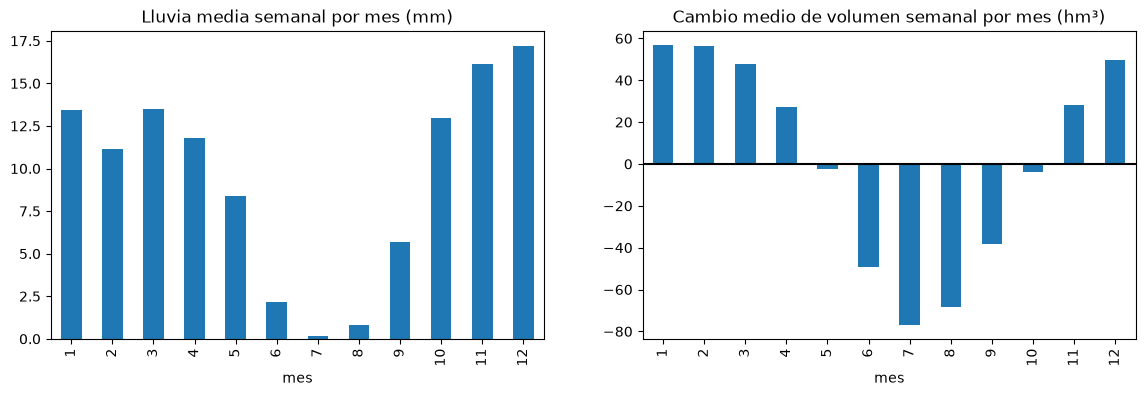

In [3]:
#Calculamos la lluvia media y el cambio medio de volumen de cada mes, para ver qué pses se llenan y se vacían los embalses.

datos = datos.dropna().copy()
datos["cambio_semanal"] = datos["volumen"].diff()
datos["mes"] = datos.index.month

por_mes = datos.groupby("mes")[["lluvia", "cambio_semanal"]].mean()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
por_mes["lluvia"].plot(kind="bar", ax=ax[0], title="Lluvia media semanal por mes (mm)")
por_mes["cambio_semanal"].plot(kind="bar", ax=ax[1], title="Cambio medio de volumen semanal por mes (hm³)")
ax[1].axhline(0, color="black")
plt.show()

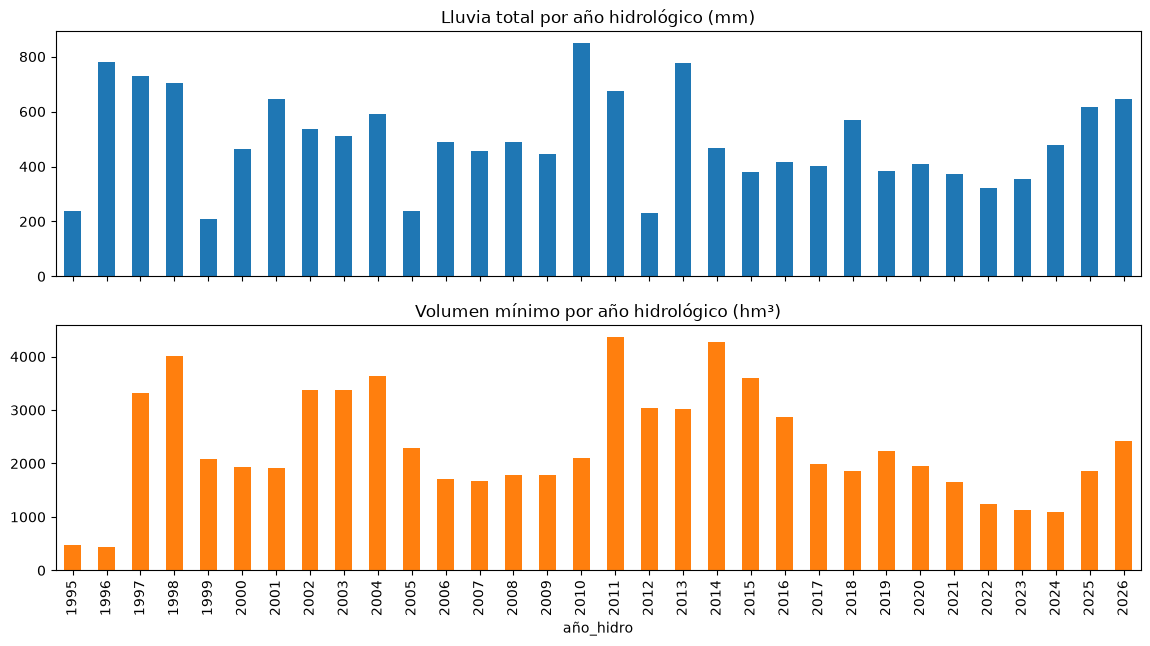

In [4]:
#Calculamos la lluvia total y el volumen minimo de cada año hidrológico (de cotuvre a septiembre) para identificar los años secos y húmedos.

datos["año_hidro"] = datos.index.year + (datos.index.month >= 10)

anual = datos.groupby("año_hidro").agg(lluvia=("lluvia", "sum"), vol_min=("volumen", "min"))
anual = anual.loc[1995:2026]

fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
anual["lluvia"].plot(kind="bar", ax=ax[0], title="Lluvia total por año hidrológico (mm)")
anual["vol_min"].plot(kind="bar", ax=ax[1], title="Volumen mínimo por año hidrológico (hm³)", color="tab:orange")
plt.show()

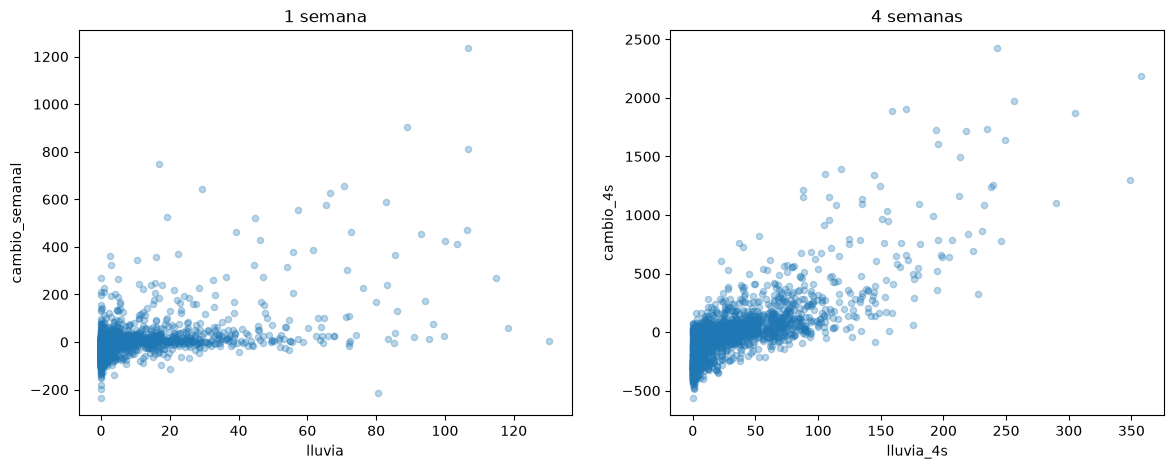

Correlación 1 semana: 0.51
Correlación 4 semanas: 0.78


In [5]:
#Comparamos la lluvia con el cambio de volumen a 1 y 4 semanas, para ver si al llover más sube más el embalse y qué escala de tiempo
#se ve mejor la relación.

datos["lluvia_4s"] = datos["lluvia"].rolling(4).sum()
datos["cambio_4s"] = datos["volumen"].diff(4)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
datos.plot.scatter(x="lluvia", y="cambio_semanal", ax=ax[0], alpha=0.3, title="1 semana")
datos.plot.scatter(x="lluvia_4s", y="cambio_4s", ax=ax[1], alpha=0.3, title="4 semanas")
plt.show()

print("Correlación 1 semana:", round(datos["lluvia"].corr(datos["cambio_semanal"]), 2))
print("Correlación 4 semanas:", round(datos["lluvia_4s"].corr(datos["cambio_4s"]), 2))

In [ ]:
# Conclusiones:
# - A 1 semana la correlación es débil (0,51): hay semanas con más de 100 mm en las que el volumen apenas sube,
#   porque el agua aún no ha llegado a los embalses o la absorbe el suelo.
# - A 4 semanas la relación es mucho más clara (0,78): la lluvia acumulada explica mejor el cambio de volumen.
# - No es lineal: con poca lluvia (<50 mm) apenas sube, y a partir de ahí sube cada vez más (curva y abanico).
# - Para el modelo: usar lluvia acumulada en lugar de semanal, y los árboles captarán mejor la curva que la lineal.

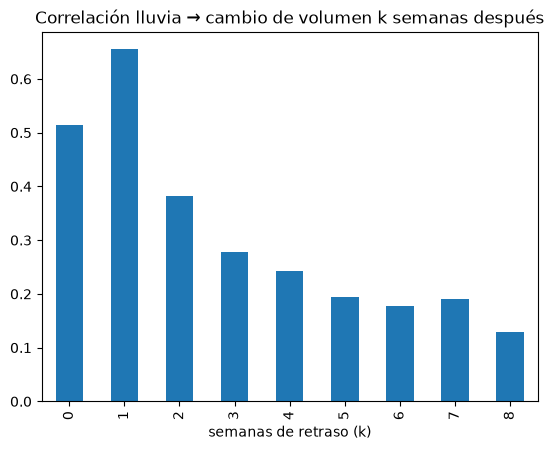

In [6]:
#Calculamos la correlación entre la lluvia de una semana y el cambio de volumen de las semanas siguientes, para saber cuánto tarda 
#en llegar a los embalses.

retrasos = range(0, 9)
corr = [datos["lluvia"].corr(datos["cambio_semanal"].shift(-k)) for k in retrasos]

pd.Series(corr, index=retrasos).plot(kind="bar", title="Correlación lluvia → cambio de volumen k semanas después")
plt.xlabel("semanas de retraso (k)")
plt.show()

In [7]:
#Comparamos cuánto sube el voluen con la misma cantidad de lluvia en otoño y en invierno, para comprobar si el sulo seco tras el verano 
#absorbe la lluvia.

datos["epoca"] = datos["mes"].map({10: "otoño", 11: "otoño", 12: "invierno", 1: "invierno", 2: "invierno", 3: "invierno"})
datos["tramo_lluvia"] = pd.cut(datos["lluvia_4s"], bins=[0, 25, 50, 100, 200, 400])

tabla = datos.dropna(subset=["epoca"]).pivot_table(index="tramo_lluvia", columns="epoca", values="cambio_4s", aggfunc="mean", observed=True)
tabla.round(0)

epoca,invierno,otoño
tramo_lluvia,,
"(0, 25]",33.0,-61.0
"(25, 50]",115.0,-32.0
"(50, 100]",206.0,31.0
"(100, 200]",572.0,211.0
"(200, 400]",1352.0,810.0


In [ ]:
# Conclusiones del suelo seco:
# - Con la misma lluvia, el volumen sube mucho menos en otoño que en invierno (50-100 mm: +31 frente a +206 hm³).
# - En otoño, con menos de 50 mm el volumen sigue bajando: el suelo seco tras el verano absorbe la lluvia.
# - Para el modelo: el efecto de la lluvia depende de la época y de la lluvia acumulada antes (suelo húmedo o seco).
#   Variables: mes/semana del año y lluvia acumulada desde el inicio del año hidrológico. Los árboles captan esta interacción.

In [8]:
#En semanas sin lluvia, vemos cuánto baja el volumen según la temperatura, para medir el efecto del calor (evaporación y riego).

secas = datos[datos["lluvia"] < 1].copy()
secas["tramo_temp"] = pd.cut(secas["tmed"], bins=[0, 10, 15, 20, 25, 30, 35])

secas.groupby("tramo_temp", observed=True)["cambio_semanal"].agg(["mean", "count"]).round(0)

,mean,count
tramo_temp,,
"(0, 10]",10.0,62
"(10, 15]",11.0,129
"(15, 20]",13.0,93
"(20, 25]",-31.0,188
"(25, 30]",-70.0,305
"(30, 35]",-65.0,31
